# The Scoreboard

### Seven swaps, one table: what was better, and what it cost

Notebooks 01 to 07 each took one technique from an agent's memory, built it the way it is usually built, showed where it breaks, swapped the judgement inside it for a decision model, and measured both on the same labelled data. Each ended with a scorecard. This notebook puts the seven scorecards side by side and reads them together.

Nothing here calls a model. Every number comes from the `results/` files the seven notebooks wrote, so run them first.

| Part | What you will see |
|---|---|
| 1 · The seven scorecards | One row per swap: today, the decision model, the verdict |
| 2 · One chart | The main measure of every swap, today against the decision model |
| 3 · What it costs | Time and money, today against the decision model |
| 4 · The pattern | Index for recall, predicate for precision |
| 5 · Where it pays | Three rules of thumb, checked against the results |

**Live path.**

| Section | What to show | Minutes |
|---|---|---|
| ⭐ 1.2 | The scoreboard | 3 |
| ⭐ 2.1 | The chart | 2 |
| ⭐ 4.1 | The pattern table | 2 |

# Part 1 · The Seven Scorecards

## 1.1 · Read the results

Each swap notebook recorded its scorecard as one `summary` row. The verdict on every measure is a paired bootstrap over that notebook's labelled items: **better** or **worse** only when the gain stays on one side of zero in 95% of resamples, **level** otherwise.

In [1]:
import sys
sys.path.insert(0, "..")

import harness
import numpy as np
import pandas as pd

cards = []
for path in sorted(harness.RESULTS.glob("0[1-7]_*.jsonl")):
    log = pd.read_json(path, lines=True)
    cards += log[log["kind"] == "summary"].to_dict("records")
print(len(cards), "scorecards:")
for card in cards:
    print(" ", card["swap"])

7 scorecards:
  Swap 1 of 7 · Semantic chunking
  Swap 2 of 7 · Reranking
  Swap 3 of 7 · Semantic cache
  Swap 4 of 7 · Memory routing
  Swap 5 of 7 · Consolidation and dedup
  Swap 6 of 7 · Memory extraction
  Swap 7 of 7 · Tool selection


## 1.2 · ⭐ The scoreboard

In [2]:
MARK = {"better": "✅ better", "level": "➖ level", "worse": "❌ worse"}

def also(card):
    return "; ".join(f"{name} {v['today']:.2f} → {v['model']:.2f} {MARK[v['verdict']]}" for name, v in (card["also"] or {}).items())

pd.set_option("display.max_colwidth", 120)
board = pd.DataFrame([{
    "swap": card["swap"].split("· ", 1)[1],
    "today": card["today_label"],
    "measure": card["measure"],
    "today scored": round(card["today"], 2),
    "decision model scored": round(card["model"], 2),
    "verdict": MARK[card["verdict"]],
    "also measured": also(card),
} for card in cards])
board

,swap,today,measure,today scored,decision model scored,verdict,also measured
0,Semantic chunking,semantic p95,retrieval hit rate,0.95,0.93,➖ level,utilisation 0.04 → 0.07 ✅ better
1,Reranking,cross-encoder,nDCG@5,0.71,0.89,✅ better,recall@5 0.83 → 0.97 ✅ better; first is relevant 0.60 → 0.78 ✅ better
2,Semantic cache,cosine 0.9,right decisions,0.58,0.98,✅ better,paraphrases served 0.10 → 1.00 ✅ better
3,Memory routing,nearest store,right route,0.45,0.67,✅ better,two-store turns 0.00 → 0.67 ✅ better
4,Consolidation and dedup,cut-off 0.95,right action,0.20,0.88,✅ better,contradictions caught 0.00 → 1.00 ✅ better
5,Memory extraction,prompt on every turn,turns handled right,0.97,1.00,➖ level,
6,Tool selection,top 3 by similarity,right tool first,0.71,0.96,✅ better,no wrong tool call 0.95 → 1.00 ✅ better


**What this shows:** **five of the seven swaps are better on their main measure, two are level, and none is worse.**
- **Better:** reranking (nDCG@5 0.71 → 0.89), the semantic cache (right decisions 0.58 → 0.98), memory routing (right route 0.45 → 0.67), consolidation (right action 0.20 → 0.88) and tool selection (right tool first 0.71 → 0.96). Every one of their second measures is better too.
- **Level:** chunking finds the answer as often as today (hit rate 0.95 and 0.93) but returns twice as much answer per token (utilisation better). Extraction handles every turn right against 58 of 60, a gap too small to call on 60 turns, and its gain is cost: 23 of 60 prompt calls skipped.

# Part 2 · One Chart

## 2.1 · ⭐ Today against the decision model

Every main measure runs from 0 to 1, and higher is better, so the seven sit on one axis.

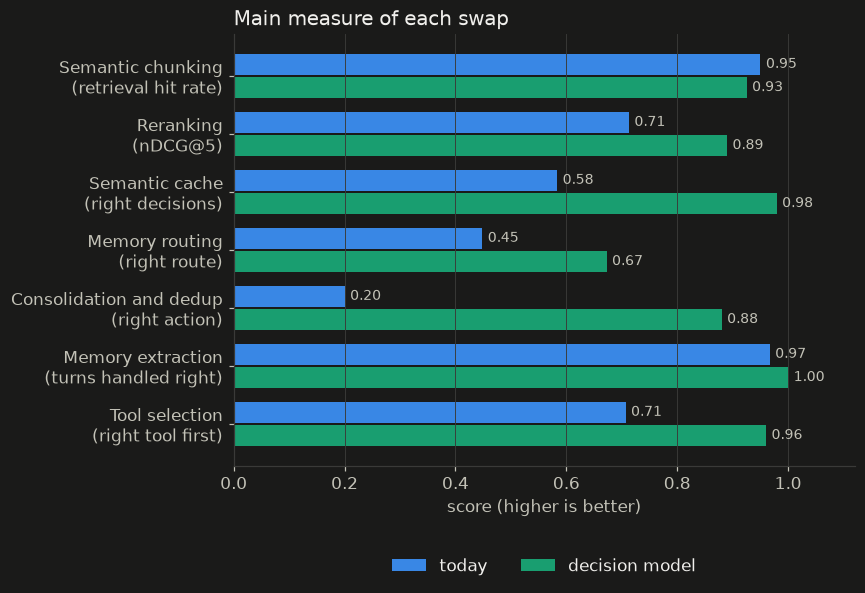

In [3]:
from harness import charts

charts.style()
fig, ax = charts.paired_bars(
    [{"name": f"{card['swap'].split('· ', 1)[1]}\n({card['measure']})", "today": card["today"], "model": card["model"]} for card in cards],
    title="Main measure of each swap", xlabel="score (higher is better)", left="today", right="decision model",
    size=(8, 5.6))

# Part 3 · What It Costs

## 3.1 · Time and money

Each scorecard also recorded latency and cost in the unit that suits its swap: per document, per lookup, per turn or per 100 turns. Decision models are priced at Liquid's hosted rate for d1; run locally they cost nothing, and the time is this laptop's GPU.

In [4]:
rows = []
for card in cards:
    for name, (today, model) in (card["extra"] or {}).items():
        if any(word in name for word in ("ms", "second", "usd")):
            rows.append({"swap": card["swap"].split("· ", 1)[1], "item": name, "today": today, "decision model": model})
pd.DataFrame(rows).set_index(["swap", "item"])

today decision model
swap                    item                                           
Semantic chunking       seconds per document         1.8           26.9
                        usd per document        0.000118       0.000534
Reranking               ms per 20 candidates          14            963
                        usd per 1,000 queries  0 (local)          0.042
Semantic cache          ms per lookup                187            421
                        usd per 1,000 lookups     0.0002         0.0084
Memory routing          ms per turn                  175            165
                        usd per 1,000 turns       0.0002         0.0053
Consolidation and dedup ms per pair                   19            107
                        usd per 1,000 pairs       0.0002         0.0037
Memory extraction       usd per 100 turns        0.00371        0.00294
                        seconds per 100 turns         76             98
Tool selection          ms per turn                 1071           1065
                        usd per 1,000 turns       0.0544         0.0408

**What this shows:** the price is mostly **time on this laptop**. The decision model runs on the laptop's GPU, so it is slower than an embedding lookup or a small cross-encoder: about 70 times slower for reranking (963 ms against 14 ms per 20 candidates), about twice as slow for the cache. Where the alternative was an LLM call (tool selection, and the LLM router in notebook 04), it is as fast or faster, and cheaper. In money every swap is fractions of a cent per thousand decisions at Liquid's hosted rate, and nothing at all run locally.

# Part 4 · The Pattern

## 4.1 · ⭐ Index for recall, predicate for precision

In every swap, the first step stayed geometric: embeddings, vector search and similarity found the candidates, cheaply and at scale. What changed is the decision made on those candidates. A similarity score answers "how close are these?", which stands in for the question we actually have. The decision model asks that question directly, as a predicate.

<img src="img/reference/p34_the_pattern.png" alt="Index for recall, predicate for precision: what similarity measures against what the predicate asks, for each use case." width="872">

<sub>From <i>The Decision on Decision Models</i>, page 34. The full PDF is in <code>docs/</code>.</sub>

In [5]:
PATTERN = [
    ("Semantic chunking", "Are neighbouring sentences close?", "Does a new topic start here?", "yes / no"),
    ("Reranking", "Is the chunk on topic?", "Does it answer the query?", "probability, sorted"),
    ("Semantic cache", "Is the query close to a cached one?", "Can this cached answer serve this query?", "yes / no"),
    ("Memory routing", "Which store description is nearest?", "Which memory types does this need?", "yes / no per type"),
    ("Consolidation and dedup", "Are these near-identical?", "Same, refines, contradicts, complements or unrelated?", "choice of five"),
    ("Memory extraction", "Nothing: it always runs", "Is anything here durable, and what type?", "yes / no, then choice"),
    ("Tool selection", "Is the tool on topic?", "Which tool does this need, if any?", "choice, with none"),
]
verdicts = {card["swap"].split("· ", 1)[1].lower(): MARK[card["verdict"]] + f" on {card['measure']}" for card in cards}
pd.DataFrame([{"use case": use, "what similarity measures": sim, "what the decision model asks": ask,
               "answer shape": shape, "result here": verdicts.get(use.lower(), "")}
              for use, sim, ask, shape in PATTERN])

,use case,what similarity measures,what the decision model asks,answer shape,result here
0,Semantic chunking,Are neighbouring sentences close?,Does a new topic start here?,yes / no,➖ level on retrieval hit rate
1,Reranking,Is the chunk on topic?,Does it answer the query?,"probability, sorted",✅ better on nDCG@5
2,Semantic cache,Is the query close to a cached one?,Can this cached answer serve this query?,yes / no,✅ better on right decisions
3,Memory routing,Which store description is nearest?,Which memory types does this need?,yes / no per type,✅ better on right route
4,Consolidation and dedup,Are these near-identical?,"Same, refines, contradicts, complements or unrelated?",choice of five,✅ better on right action
5,Memory extraction,Nothing: it always runs,"Is anything here durable, and what type?","yes / no, then choice",➖ level on turns handled right
6,Tool selection,Is the tool on topic?,"Which tool does this need, if any?","choice, with none",✅ better on right tool first


# Part 5 · Where It Pays

## 5.1 · Three rules of thumb, checked

The three rules, as stated before the measurements:

<img src="img/reference/p35_where_it_pays.png" alt="Two rules of thumb (strongest where a false positive is costly; decide at write time where you can) and where it does not pay." width="872">

<sub>From <i>The Decision on Decision Models</i>, page 35. The full PDF is in <code>docs/</code>.</sub>

And as checked against the seven scorecards:

**Rule 1 · Strongest where a false positive is costly.** Confirmed. The three largest gains are where similarity says yes and the answer is no: a contradiction treated as a duplicate (consolidation: 0 → 10 of 10 contradictions caught), a near miss served from the cache (paraphrases 2 → 20 of 20, wrong answers 2 → 1), and a tool on the right topic but the wrong action (wrong tool calls 4 → 0).

**Rule 2 · Decide at write time where you can.** Chunking, consolidation and extraction run once, when data comes in, or on a schedule. Their extra time (tens of seconds per document, 0.1 seconds per pair) is paid once and nobody waits for it. Reranking, the cache, routing and tool selection run on every turn, so their milliseconds are felt.

**Rule 3 · Where it does not pay: first-stage recall, and cheap mistakes.** No swap replaced the index: embeddings and vector search still found the candidates in every notebook, and the decision model judged the few they returned. Reranking on a laptop is the clearest hot-path cost, at about 960 ms a turn, so measure the milliseconds first. And where today's method was already good (the extraction prompt handled 58 of 60 turns), the gain is cost, not accuracy.

> 📌 **Key Takeaways**
> - Five of seven swaps were better on their main measure, two were level, none was worse.
> - The biggest gains were where similarity says yes and the answer is no: deduplication, the cache and tool selection.
> - Every swap kept the index for recall. The decision model replaced the judgement on what the index returned: index for recall, predicate for precision.
> - The cost is time on the hot path. Decisions at write time hide it; decisions on every turn must budget for it.
> - One synthetic transcript and label sets of 40 to 75 items: read this as a way to run the comparison on your own data, not as a ranking.